### Case Study: **Þingmúli and Hekla, Iceland**

*Primitive to Evolved - Subalkaline Tholeiitic*

[![Documentation](https://img.shields.io/badge/docs-latest-blue?logo=read-the-docs&logoColor=white)](https://hades-obol.readthedocs.io/en/latest/)
[![GitHub](https://img.shields.io/badge/GitHub-Hades-red?logo=github)](https://github.com/Jack6228/Hades)
[![PyPI](https://img.shields.io/pypi/v/hades-obol?logo=pypi&logoColor=white)](https://pypi.org/project/hades-obol/)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jack6228/Hades/blob/main/examples/iceland/thingmuli_hekla.ipynb)

Þingmúli is an off-rift, central volcano in Eastern Iceland. Samples from Þingmúli follow two distinct liquid lines of descent. One is a classic tholeiitic fractional crystallisation trend, and the other (alongside rocks from Hekla), follow an assimilation/magma mixing and fractional crystallisation trend. Here, we use Hades to model the pure fractional crystallisation trend.  

> Note: This notebook is not intended to act as a tutorial directly, but to demonstrate this case study. See the [Hades Python Tutorial ↗](https://hades-obol.readthedocs.io/en/latest/api/tutorial.html) for more detailed explanations.

**Key links**: [GitHub Folder ↗](https://github.com/Jack6228/Hades/tree/main/examples/iceland) | [Documentation Page ↗](https://hades-obol.readthedocs.io/en/latest/case_studies/iceland/index.html) | [API Reference ↗](https://hades-obol.readthedocs.io/en/latest/api/index.html)

---

**Model Setup**

In [1]:
# Import the Obol class from the hades module and initialise a new model
from hades import Obol
model = Obol.newModel()

# Load the data suite
model.load_data_suite('./thingmuli_hekla.xlsx')

# Select samples to form the projected LLOD
model.select_initial_composition([None, 'T3-01', 'T7-03', 'auto', 'auto', 'T3-12'])

hades-obol v0.8.4. This is a pre-release version. Check for updates using hades.check_for_updates()
Primary       : n/a
Primitive     : 'T3-01'
Basic         : 'T7-03'
Intermediate  : 'H4 11' [auto]
Evolved       : '0409-14' [auto]
End           : 'T3-12'
5/6 phases have been set with user-provided initial compositions.


**Customisation**

Here, we can configure KD values, contributing minerals and their compositions**Customise Model Configuration**

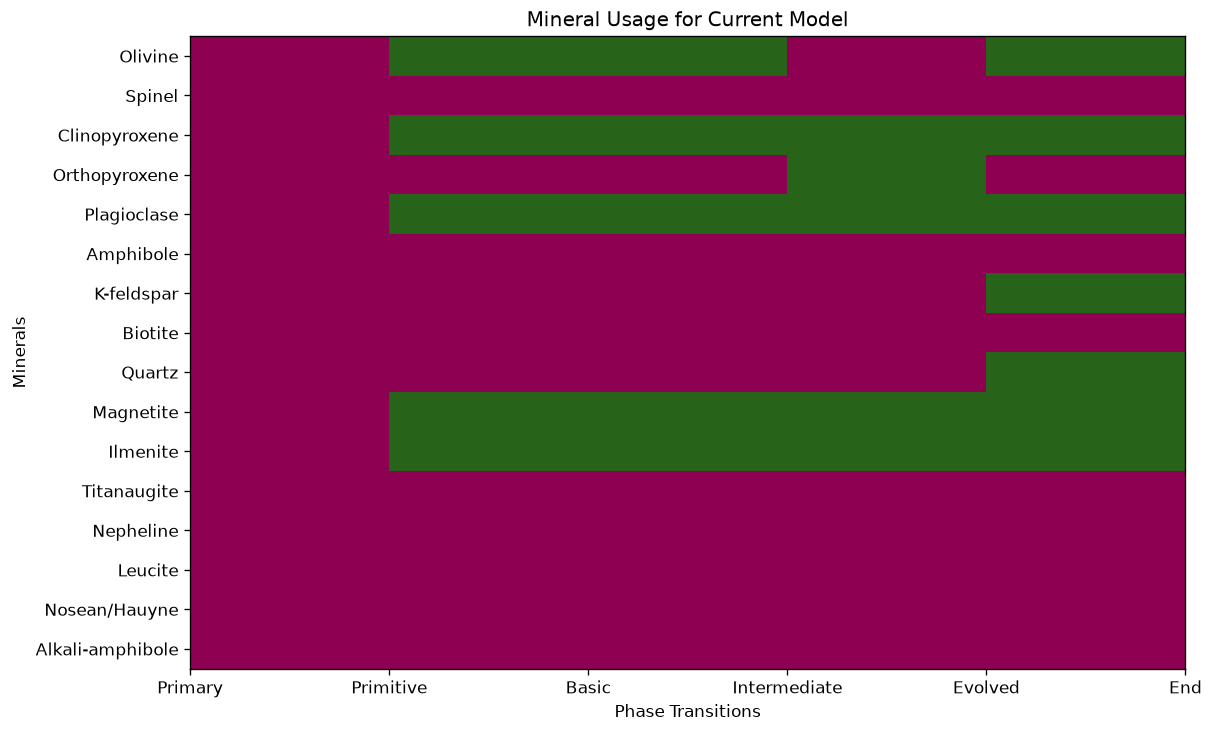

In [2]:
# Define which minerals contribute to the assemblage and in which phases
model.set_mineral_usage(
    __spinel=False,
    __cpx=True,
    __opx=False,
    intermediate__opx=True,
    __plagioclase=True,
    __mag=True,
    __ilm=True,
    __quartz=False,
    evolved__quartz=True,
)

# Optionally: view the mineral usage configuration
from hades.visuals import mineral_usage
mineral_usage(
    model,
    filename='./outputs/mineral_usage.png',
)

In [3]:
# Specify the mineralogical compositions for minerals and phases (in wt.%)
model.set_mineralogies(
    basic__plagioclase =        [51.10, 0.07, 30.07, 0.78,  0.17, 14.39, 3.33, 0.08 ],
    intermediate__plagioclase = [57.83, 0.04, 26.13, 0.51,  0.03,  9.06, 6.08, 0.31 ],
    evolved__plagioclase =      [59.90, 0.02, 24.85, 0.38,  0.01,  7.15, 7.14, 0.54 ],
    basic__cpx =         [50.78, 1.08, 1.97, 12.28, 14.07, 19.51, 0.31, 0.00 ],
    intermediate__cpx =  [48.86, 0.76, 1.65, 22.42,  9.21, 16.86, 0.24, 0.00 ],
    evolved__cpx =       [47.21, 0.44, 0.95, 29.34,  3.11, 18.70, 0.25, 0.00 ],
)

Normalising composition for basic__plagioclase to 100 wt%. Original sum: 99.99
Normalising composition for intermediate__plagioclase to 100 wt%. Original sum: 99.99
Normalising composition for evolved__plagioclase to 100 wt%. Original sum: 99.99


In [4]:
# Set experimental or literature-based KD values for the minerals and phases 
model.set_KDs(
    __plagioclase=0.95, 
    __cpx=0.25,
)

**Optimisation**

In [5]:
# Run stages 2 through 5 (primitive - basic through to evolved - end)
model.run(2)
model.run(3)
model.run(4)
model.run(5)

> Optimisation completed with cost = 0.06 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 0.88 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 1.02 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 2.72 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'


We can view the results for the entire model:

In [6]:
model.summary()

                        P-B        B-I        I-E        E-e     |     Total   
------------------------------------------------------------------------------------------------
            Type  |    Majors     Majors     Majors     Majors   |            
            Cost  |      0.06       0.88       1.02       2.72   |            
------------------------------------------------------------------------------------------------
               F  |        18         70         54         12   |       100    %
         Olivine  |    27.341      7.361                20.818   |    10.472    wt.%
          Spinel  |                                              |              wt.%
   Clinopyroxene  |     1.885     38.010     19.865     31.317   |    28.011    wt.%
   Orthopyroxene  |                          10.535              |     1.554    wt.%
     Plagioclase  |    56.306     42.710     57.479      1.060   |    46.979    wt.%
       Amphibole  |                                          

**Visualising Results**

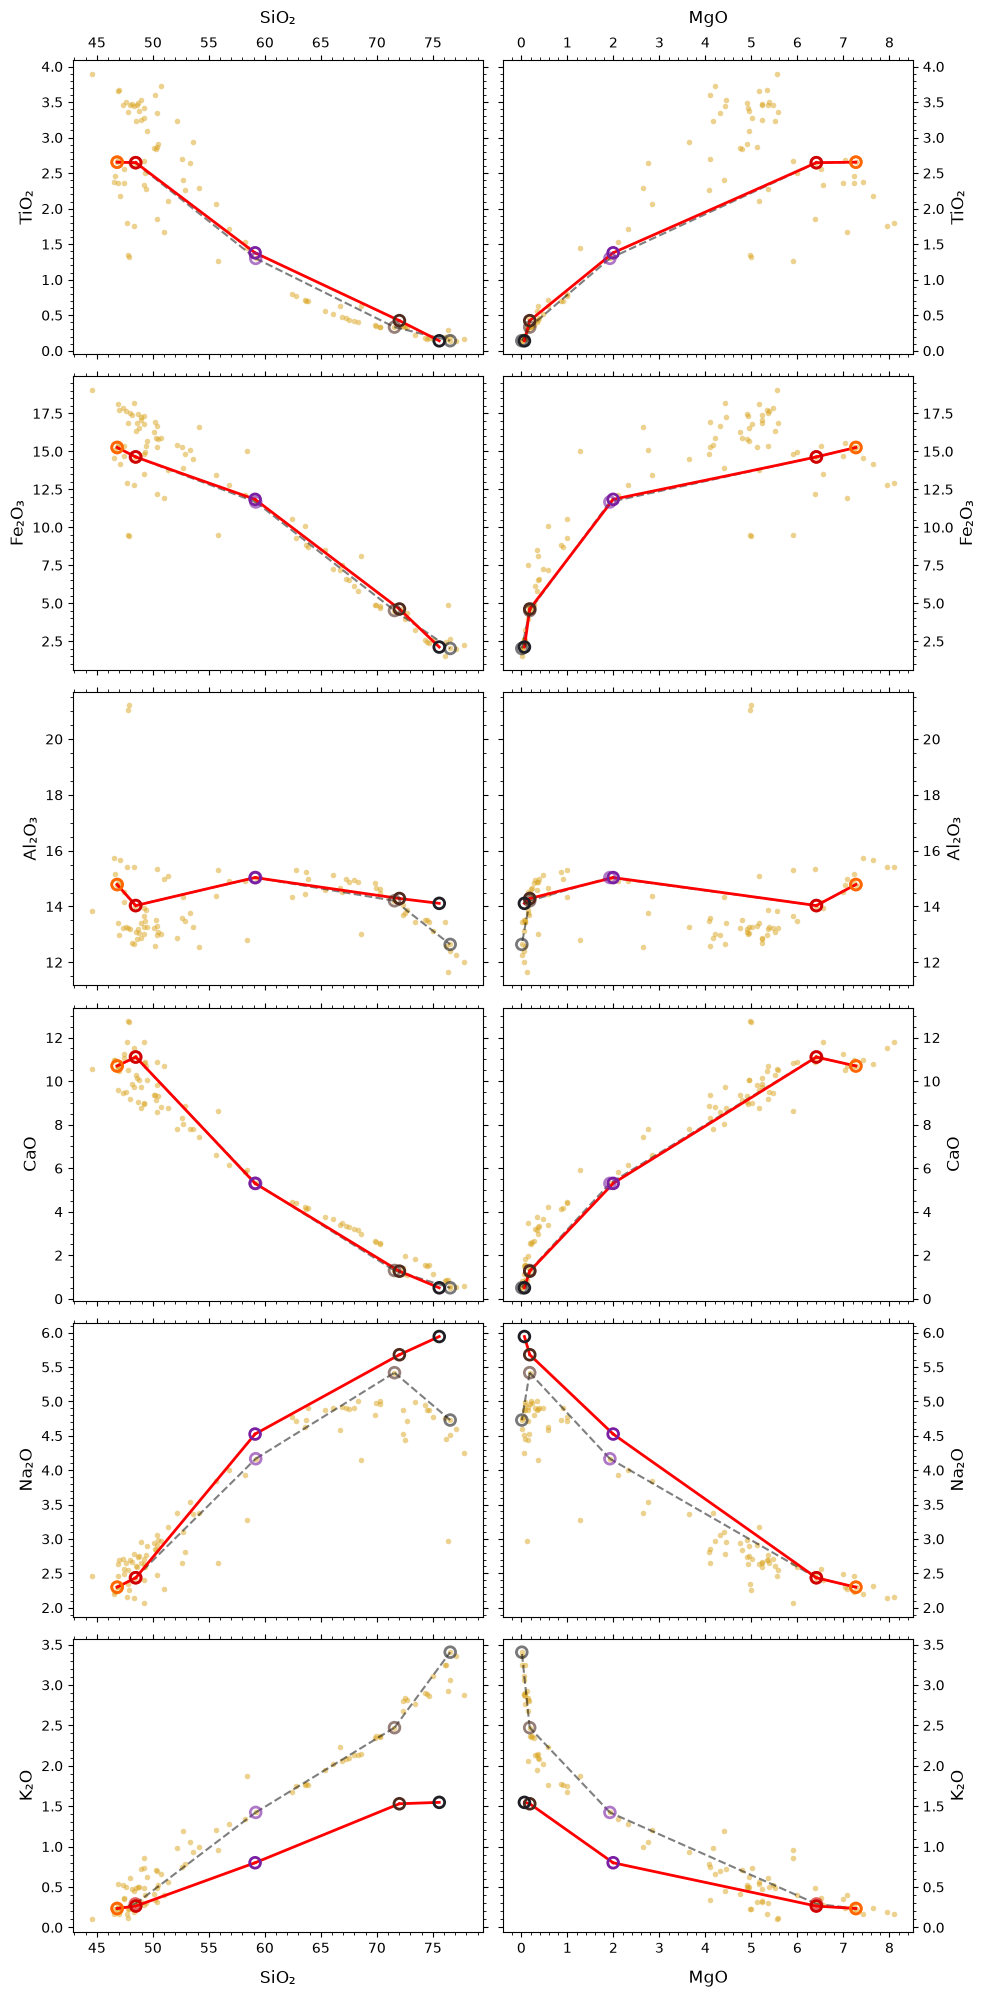

In [7]:
from hades.visuals import bivar
bivar(
    model, 
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename="./outputs/bivariate_plots.png"
)

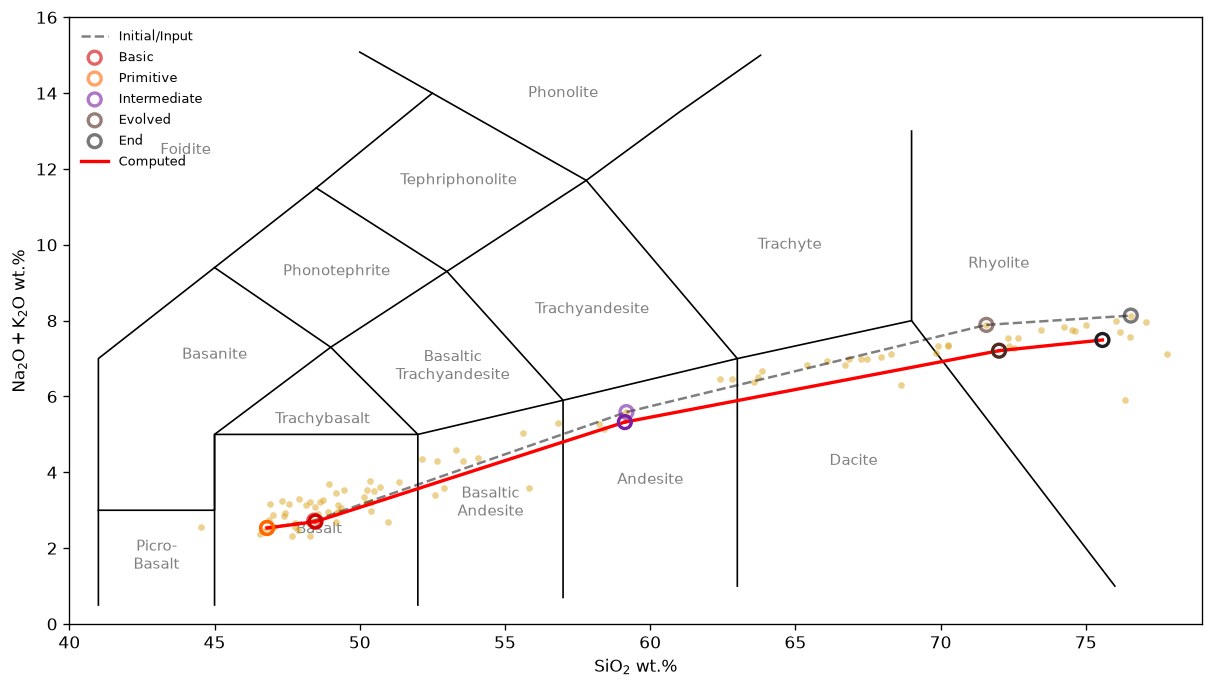

In [8]:
from hades.visuals import tas
tas(
    model, 
    filename="./outputs/tas_diagram.png"
)

**Trace Element Modelling**

To model trace elements, we perturb the optimal solution found above with your chosen wt.%s of accessory minerals. Hades re-models fractional crystallisation with the new bulk composition and outputs the trace element results.

We can use trial-and-error to find the best-fitting accessory mineral proportions, utilising the ``harker()`` function to visualise the results.

Trace element analyses were run. Using trace results for mineral proportions.
Trace element analyses were run. Using trace results for mineral proportions.
Trace element analyses were run. Using trace results for mineral proportions.


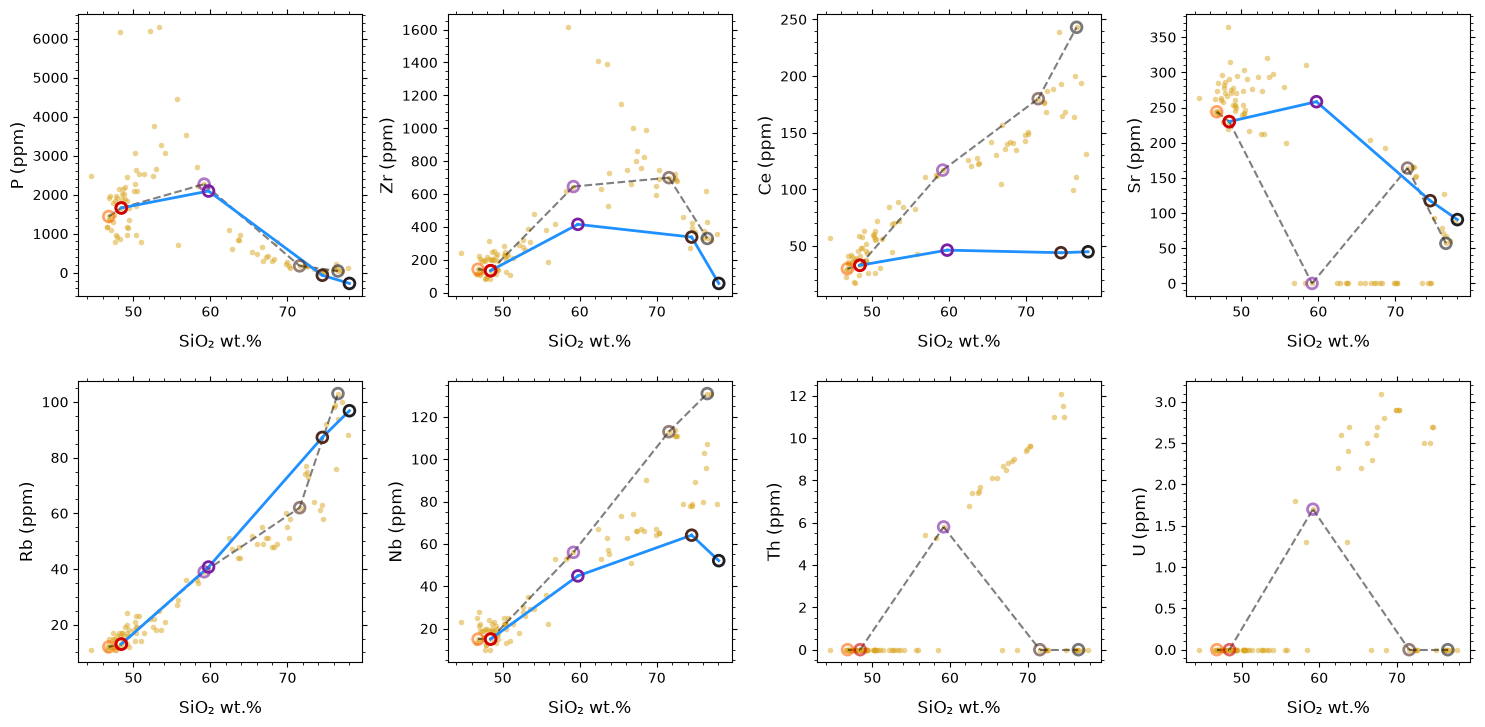

In [9]:
# For each stage, we provide the wt.% of apatite, zircon, monazite and allanite

# No accessory minerals in the primitive stage (does not need to be run)
# model.runTraces(2, [0, 0, 0, 0])
# 0.75 wt.% apatite in the basic-intermediate stage
model.runTraces(3, [0.75, 0, 0, 0])
# 2 wt.% apatite and 0.1 wt.% ziron in the intermediate-evolved stage
model.runTraces(4, [2, 0.1, 0, 0])
# 0.75 wt.% apatite and 0.5 wt.% zircon in the evolved stage
model.runTraces(5, [0.75, 0.5, 0, 0])

from hades.visuals import harker
harker(
    model, 
    y_order=['P', 'Zr', 'Ce', 'Sr', 'Rb', 'Nb', 'Th', 'U'], 
    nrows=2,
    filename="./outputs/harker_plots.png"
)

In [10]:
model.summary()

                        P-B        B-I        I-E        E-e     |     Total   
------------------------------------------------------------------------------------------------
            Type  |    Majors     Traces     Traces     Traces   |            
            Cost  |      0.06        0.00       0.00       0.00  |            
------------------------------------------------------------------------------------------------
               F  |        18         70         54         12   |       100    %
         Olivine  |    27.341      7.306                20.558   |     6.208    wt.%
          Spinel  |                                              |              wt.%
   Clinopyroxene  |     1.885     37.725     19.448     30.925   |    34.227    wt.%
   Orthopyroxene  |                          10.314              |     1.902    wt.%
     Plagioclase  |    56.306     42.390     56.272      1.047   |    44.170    wt.%
       Amphibole  |                                          

We can also re-visualise the bivariate diagrams with the trace modelled results (``mode='traces'``) to see the impact on major oxide elements.

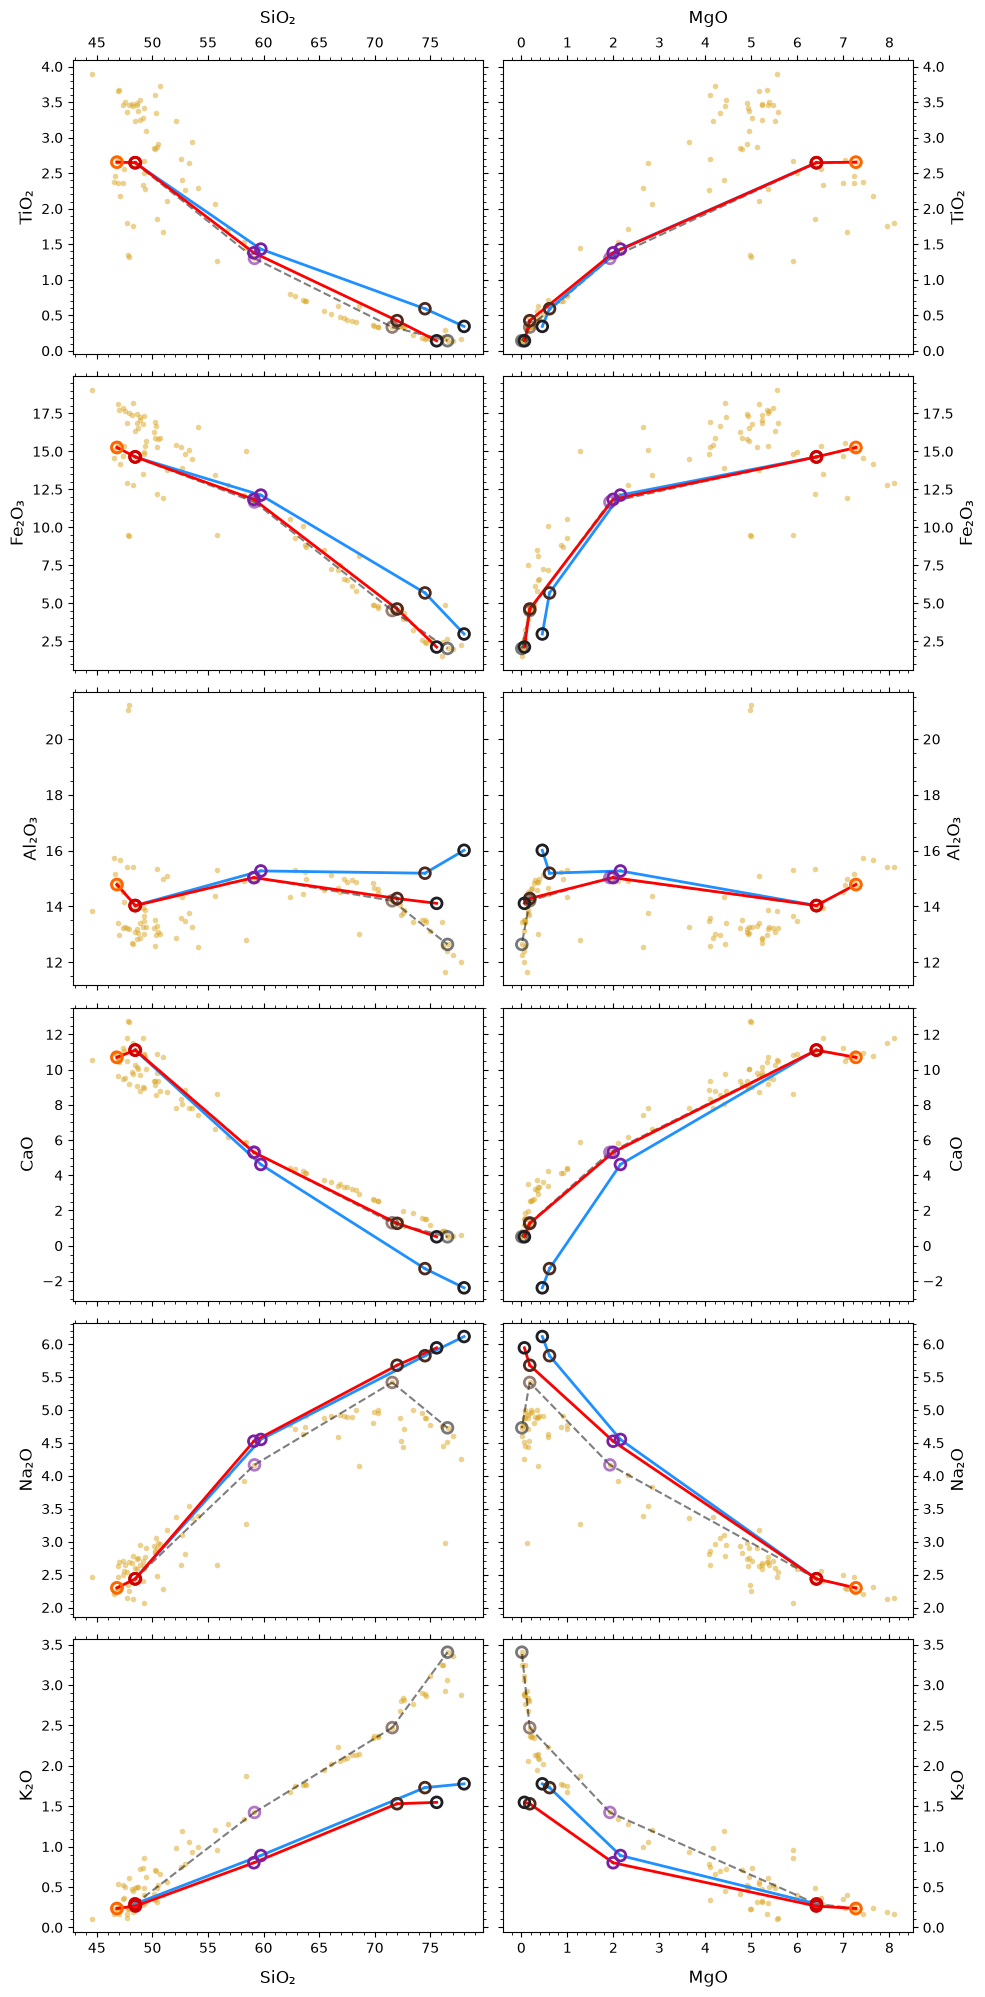

In [11]:
# Plot bivariate plots for the major oxides and save to a file
from hades.visuals import bivar
bivar(
    model, 
    mode='traces',
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/bivariate_plots_trace_elements.png',
)

**Export Results**

Note that we can export results prior to or without trace element modelling, which will omit such results from the output files.

In [12]:
model.savePDF('./outputs/results.pdf')
model.saveData('./outputs/data_output.xlsx')

PDF compilation completed. Output saved to ./outputs/results.pdf
Excel file saved successfully: ./outputs/data_output.xlsx


----

**Useful Commands**

Configuration Files

Having imported data and configured our desired parameters, we can save the configuration to a ``.hades`` file. This allows us to easily reload the model configuration in the future (either in Python or the Hades Windows application) without having to re-import data or reconfigure parameters.

See the documentation for more information on [saving and loading model configurations](https://hades-obol.readthedocs.io/en/latest/user_manual/config_files.html).

In [13]:
model.save_config('./thingmuli_hekla.hades')

Successfully saved configuration to ./thingmuli_hekla.hades


To use a ``.hades`` configuration file to initialise a model, simply create a fresh model and call the ``load_config`` method with the path to the configuration file. This will automatically import the data and set all parameters as specified in the configuration file, overwriting any arguments passed to the ``newModel`` method.

In [14]:
model = Obol.newModel()
model.load_config('./thingmuli_hekla.hades')

 To adjust the population size and maximum number of generations, you can use the following code before running the model

In [15]:
# model.optimising.max_iter = 500 # default
# model.optimising.pop_size = 50  # default